Installing PySR...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.3/99.3 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.3/253.3 kB 5.7 MB/s eta 0:00:00
[juliapkg] Found dependencies: /usr/local/lib/python3.12/dist-packages/juliapkg/juliapkg.json
[juliapkg] Found dependencies: /usr/local/lib/python3.12/dist-packages/juliacall/juliapkg.json
[juliapkg] Found dependencies: /usr/local/lib/python3.12/dist-packages/pysr/juliapkg.json
[juliapkg] Locating Julia 1.10.3 - 1.11
[juliapkg] WARNING: You have Julia 1.12.6 installed but 1.10.3 - 1.11 is required.
[juliapkg]   It is recommended that you upgrade Julia or install JuliaUp.
[juliapkg] Querying Julia versions from https://julialang-s3.julialang.org/bin/versions.json
[juliapkg] WARNING: About to install Julia 1.11.9 to /root/.julia/environments/pyjuliapkg/pyjuliapkg/install.
[juliapkg]   If you use juliapkg in more than one environment, y

/usr/local/lib/python3.12/dist-packages/pysr/deprecated.py:10: FutureWarning: The `install` function has been removed. PySR now uses the `juliacall` package to install its dependencies automatically at import time. 
  warnings.warn(


Saving ABG_LINEAR_restricted_results - Copy.xlsx to ABG_LINEAR_restricted_results - Copy.xlsx

STARTING EVOLUTIONARY SYMBOLIC REGRESSION (PySR)

>> Training PySR for: moving_away
   Raw Equation: u*(-4.864719)
   ⭐ Final Verified Equation (ΔPL): -4.864719*u
   Complexity Score: 2

>> Training PySR for: moving_in
   Raw Equation: u - 1.3378164
   ⭐ Final Verified Equation (ΔPL): u - 1.3378164
   Complexity Score: 2

=== GLOBAL RESULTS COMPARISON ===
Split      Model     RMSE      MAE       R2  Complexity
Train   Base ABG 6.945533 5.951336 0.167785         1.0
Train ABG + PySR 2.932913 2.168125 0.851604         2.0
 Test   Base ABG 7.311222 6.203709 0.043814         1.0
 Test ABG + PySR 2.931139 2.240838 0.846314         2.0

=== TEST METRICS BREAKDOWN BY SCENARIO ===
   Scenario  Base ABG RMSE  PySR RMSE  PySR R2  Improvement (dB)
MOVING_AWAY          8.860      2.658    0.817             6.201
  MOVING_IN          3.315      3.343    0.820            -0.029


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

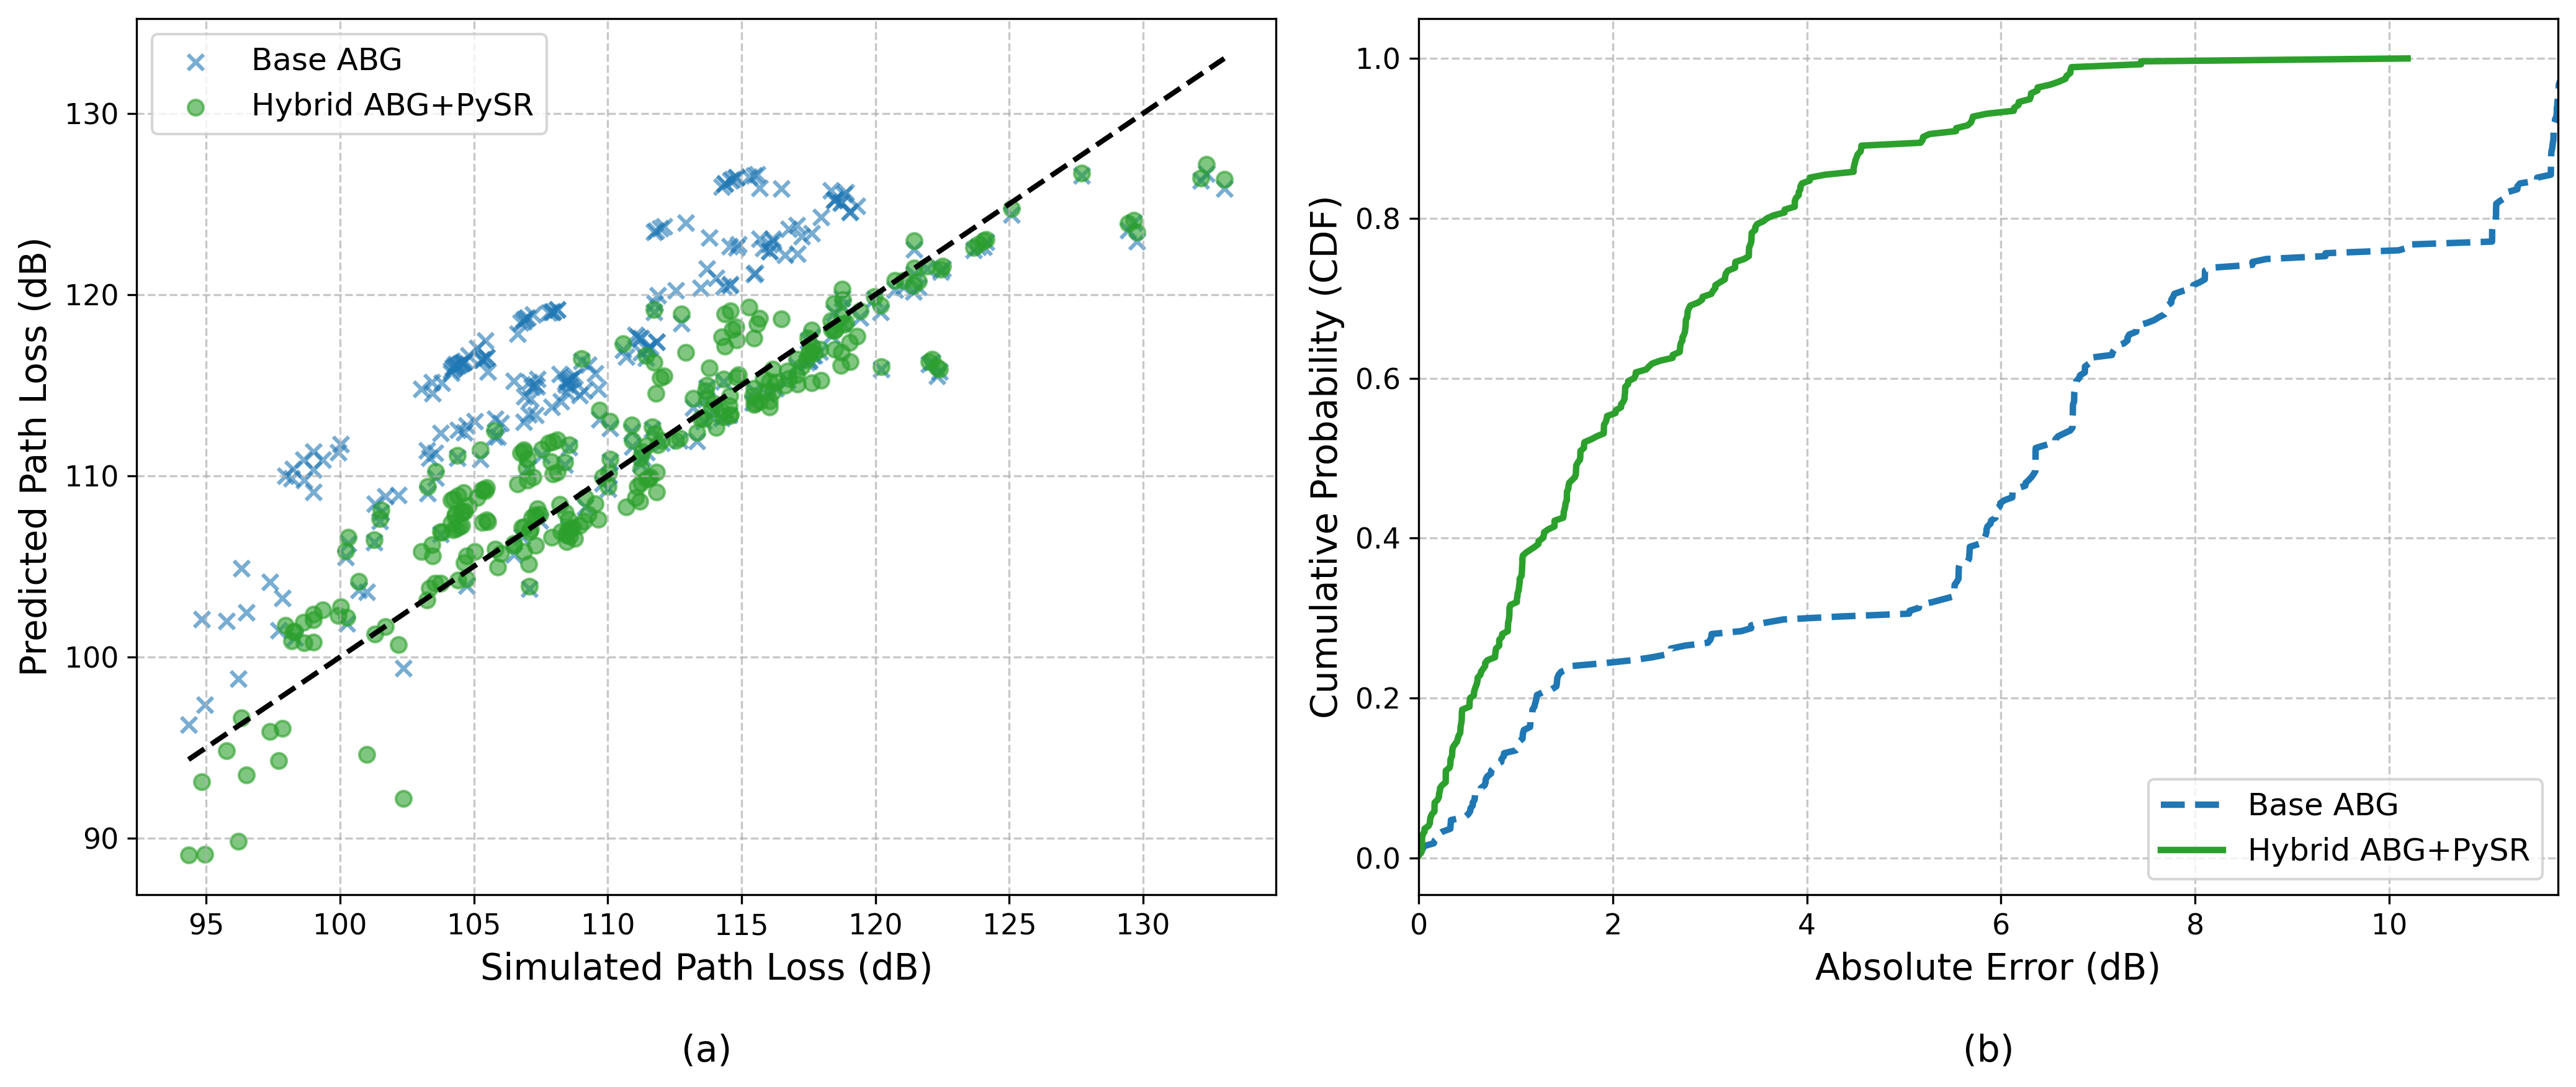


✅ تم تحديث كود PySR وإضافة التحليل التفصيلي وحفظ جميع النتائج بنجاح!


In [ ]:
# =========================================================
# 1) INSTALLATION AND JULIA BACKEND SETUP (Run this first!)
# =========================================================
print("Installing PySR...")
!pip install -q pysr

import pysr
print("Setting up Julia backend for PySR (This may take 1-2 minutes)...")
pysr.install()
print("PySR is successfully installed and ready!")

# =========================================================
# 2) ENVIRONMENT SETUP & DATA LOADING (All_prepared File)
# =========================================================
import os, sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pysr import PySRRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import sympy
from sympy.parsing.sympy_parser import parse_expr

SEED = 42
TEST_SIZE = 0.20
OUTPUT_FILE = "PySR_Detailed_Results.xlsx" # تم تحديث اسم الملف

try:
    from google.colab import files
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
except Exception:
    file_name = "All_prepared_for_symbolic_regression.xlsx"

df = pd.read_excel(file_name, sheet_name="TrainingData") if "TrainingData" in pd.ExcelFile(file_name).sheet_names else pd.read_excel(file_name)

def normalize_phase(v):
    t = str(v).strip().lower().replace("-", "_").replace(" ", "_")
    return "moving_in" if t in ["movingin", "in", "approaching"] else "moving_away" if t in ["movingaway", "away", "receding"] else t

if "Phase Label" in df.columns:
    df["Phase Label"] = df["Phase Label"].apply(normalize_phase)
df = df[df["Phase Label"].isin(["moving_in", "moving_away"])].copy()

df["u"] = df["u_speed_log10_kmh"].astype(float)
df["delta_dB"] = df["delta_dB"].astype(float)
df = df.dropna(subset=["Path Loss (dB)", "ABG Path Loss (dB)", "Phase Label", "u", "delta_dB"])

train_df, test_df = train_test_split(df, test_size=TEST_SIZE, random_state=SEED, stratify=df["Phase Label"])

# =========================================================
# 3) PySR TRAINING & SYMBOLIC SIMPLIFICATION
# =========================================================
print("\n" + "="*50)
print("STARTING EVOLUTIONARY SYMBOLIC REGRESSION (PySR)")
print("="*50)

def calculate_complexity(sympy_expr):
    complexity = 0
    for node in sympy.preorder_traversal(sympy_expr):
        if isinstance(node, (sympy.Add, sympy.Mul, sympy.Pow, sympy.Function)):
            complexity += 1
    return complexity + 1

pysr_models = {}
expr_rows = []

for scenario in sorted(train_df["Phase Label"].unique()):
    print(f"\n>> Training PySR for: {scenario}")
    sub = train_df[train_df["Phase Label"] == scenario]

    model = PySRRegressor(
        niterations=200,
        binary_operators=["+", "-", "*"],
        unary_operators=[],
        maxsize=10,
        parsimony=0.001,
        model_selection="best",
        random_state=SEED,
        verbosity=0
    )

    X_train = sub[["u"]].values
    y_train = sub["delta_dB"].values
    model.fit(X_train, y_train)

    pysr_models[scenario] = model

    raw_equation = str(model.sympy()).replace("x0", "u")

    try:
        sympy_expr = parse_expr(raw_equation)
        clean_expr = sympy.simplify(sympy_expr)
        final_expr_str = str(clean_expr)
        complexity_score = calculate_complexity(clean_expr)
    except:
        final_expr_str = raw_equation
        complexity_score = len(raw_equation.replace(" ", ""))

    expr_rows.append({
        "Scenario": scenario,
        "Raw_Equation": raw_equation,
        "Simplified_Equation": final_expr_str,
        "Complexity_Score": complexity_score
    })

    print(f"   Raw Equation: {raw_equation}")
    print(f"   ⭐ Final Verified Equation (ΔPL): {final_expr_str}")
    print(f"   Complexity Score: {complexity_score}")

# =========================================================
# 4) EVALUATION, BREAKDOWN, PLOTS & EXPORT
# =========================================================
def evaluate(df_part):
    df_part = df_part.copy()
    preds = np.zeros(len(df_part))
    for scen in df_part["Phase Label"].unique():
        mask = df_part["Phase Label"] == scen
        preds[mask] = pysr_models[scen].predict(df_part[mask][["u"]].values)

    df_part["PL_ABG"] = df_part["ABG Path Loss (dB)"]
    df_part["PL_ABG_PySR"] = df_part["ABG Path Loss (dB)"] + preds
    df_part["Error_ABG"] = np.abs(df_part["Path Loss (dB)"] - df_part["PL_ABG"])
    df_part["Error_ABG_PySR"] = np.abs(df_part["Path Loss (dB)"] - df_part["PL_ABG_PySR"])
    return df_part

train_eval = evaluate(train_df)
test_eval = evaluate(test_df)

# --- 1. المقاييس الكلية (Global Metrics) ---
rows = []
for split, df_res in [("Train", train_eval), ("Test", test_eval)]:
    for name, col in [("Base ABG", "PL_ABG"), ("ABG + PySR", "PL_ABG_PySR")]:
        y, p = df_res["Path Loss (dB)"], df_res[col]
        rmse = np.sqrt(mean_squared_error(y, p))
        mae = mean_absolute_error(y, p)
        r2 = r2_score(y, p)

        comp_score = 1
        if name == "ABG + PySR":
            comp_score = np.mean([row["Complexity_Score"] for row in expr_rows])

        rows.append({
            "Split": split, "Model": name, "RMSE": rmse, "MAE": mae, "R2": r2, "Complexity": comp_score
        })
comp_df = pd.DataFrame(rows)

print("\n=== GLOBAL RESULTS COMPARISON ===")
print(comp_df.to_string(index=False))

# --- 2. المقاييس التفصيلية لكل حالة (Breakdown Metrics) ---
breakdown_rows = []
for scen in test_eval["Phase Label"].unique():
    sub = test_eval[test_eval["Phase Label"] == scen]

    rmse_abg = np.sqrt(mean_squared_error(sub["Path Loss (dB)"], sub["PL_ABG"]))
    rmse_pysr = np.sqrt(mean_squared_error(sub["Path Loss (dB)"], sub["PL_ABG_PySR"]))
    r2_pysr = r2_score(sub["Path Loss (dB)"], sub["PL_ABG_PySR"])

    breakdown_rows.append({
        "Scenario": scen.upper(),
        "Base ABG RMSE": round(rmse_abg, 3),
        "PySR RMSE": round(rmse_pysr, 3),
        "PySR R2": round(r2_pysr, 3),
        "Improvement (dB)": round(rmse_abg - rmse_pysr, 3)
    })

breakdown_df = pd.DataFrame(breakdown_rows)
print("\n=== TEST METRICS BREAKDOWN BY SCENARIO ===")
print(breakdown_df.to_string(index=False))

# --- 3. حفظ النتائج في الإكسل ---
with pd.ExcelWriter(OUTPUT_FILE) as writer:
    comp_df.to_excel(writer, sheet_name="Global_Comparison", index=False)
    breakdown_df.to_excel(writer, sheet_name="Breakdown_Metrics", index=False)
    pd.DataFrame(expr_rows).to_excel(writer, sheet_name="Equations", index=False)
    test_eval.to_excel(writer, sheet_name="Predictions", index=False)
try: files.download(OUTPUT_FILE)
except: pass

# --- 4. الرسوم البيانية ---
plt.rcParams.update({
    'font.size': 12, 'axes.labelsize': 14, 'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 12
})
plt.figure(figsize=(14, 6), dpi=300)

plt.subplot(1, 2, 1)
plt.scatter(test_eval["Path Loss (dB)"], test_eval["PL_ABG"], alpha=0.6, label="Base ABG", marker='x', color='#1f77b4')
plt.scatter(test_eval["Path Loss (dB)"], test_eval["PL_ABG_PySR"], alpha=0.6, label="Hybrid ABG+PySR", marker='o', color='#2ca02c')
plt.plot([test_eval["Path Loss (dB)"].min(), test_eval["Path Loss (dB)"].max()],
         [test_eval["Path Loss (dB)"].min(), test_eval["Path Loss (dB)"].max()], 'k--', lw=2)
plt.xlabel("Simulated Path Loss (dB)\n\n(a)")
plt.ylabel("Predicted Path Loss (dB)")
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)

plt.subplot(1, 2, 2)
err_abg = np.sort(test_eval["Error_ABG"])
err_pysr = np.sort(test_eval["Error_ABG_PySR"])
cdf_y = np.arange(1, len(err_abg) + 1) / len(err_abg)

plt.plot(err_abg, cdf_y, label='Base ABG', linewidth=2.5, linestyle='--', color='#1f77b4')
plt.plot(err_pysr, cdf_y, label='Hybrid ABG+PySR', linewidth=2.5, color='#2ca02c')
plt.xlabel("Absolute Error (dB)\n\n(b)")
plt.ylabel("Cumulative Probability (CDF)")
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(0, max(np.percentile(err_abg, 95), np.percentile(err_pysr, 95)))

plt.tight_layout()
plt.savefig("Fig_PySR_HighRes.png", dpi=600, bbox_inches='tight')
plt.savefig("Fig_PySR_Vector.pdf", format='pdf', bbox_inches='tight')
plt.show()

print("\n✅ تم تحديث كود PySR وإضافة التحليل التفصيلي وحفظ جميع النتائج بنجاح!")

In [ ]:
# رسم كافة النتائج للطرق
# =========================================================
# FINAL PLOTTING SCRIPT FOR IEEE PUBLICATION
# =========================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 1. إعدادات ستايل IEEE للرسوم البيانية ---
plt.rcParams.update({
    'font.size': 12,
    'font.family': 'serif',
    'axes.labelsize': 14,
    'axes.titlesize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'figure.dpi': 300, # دقة عالية جداً للطباعة
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

# --- 2. قراءة الملفات ---
files = {
    "DSR": "DSR_Only_Results.xlsx",
    "PySR": "PySR_Only_Results.xlsx",
    "KAN": "KAN_NN_Only_Results.xlsx"
}

# التحقق من وجود الملفات
for name, file in files.items():
    if not os.path.exists(file):
        raise FileNotFoundError(f"⚠️ يرجى رفع ملف {file} إلى Colab أولاً!")

# تحميل بيانات الاختبار (Predictions) والمقارنات
df_dsr = pd.read_excel(files["DSR"], sheet_name="Predictions")
df_pysr = pd.read_excel(files["PySR"], sheet_name="Predictions")
df_kan = pd.read_excel(files["KAN"], sheet_name="Predictions")

comp_dsr = pd.read_excel(files["DSR"], sheet_name="Comparison")
comp_pysr = pd.read_excel(files["PySR"], sheet_name="Comparison")
comp_kan = pd.read_excel(files["KAN"], sheet_name="Comparison")

# --- 3. الرسم الأول: مقارنة RMSE بالأعمدة (Bar Chart) ---
plt.figure(figsize=(10, 6))

# استخراج Test RMSE لكل نموذج
rmse_base = comp_dsr[(comp_dsr['Split'] == 'Test') & (comp_dsr['Model'] == 'Base ABG')]['RMSE'].values[0]
rmse_dsr = comp_dsr[(comp_dsr['Split'] == 'Test') & (comp_dsr['Model'] == 'ABG + DSR')]['RMSE'].values[0]
rmse_pysr = comp_pysr[(comp_pysr['Split'] == 'Test') & (comp_pysr['Model'] == 'ABG + PySR')]['RMSE'].values[0]
rmse_kan = comp_kan[(comp_kan['Split'] == 'Test') & (comp_kan['Model'] == 'ABG + KAN')]['RMSE'].values[0]

models = ['Standard ABG', 'ABG + KAN (Deep)', 'ABG + PySR (Linear)', 'ABG + DSR (Non-Linear)']
rmse_values = [rmse_base, rmse_kan, rmse_pysr, rmse_dsr]
colors = ['#d62728', '#1f77b4', '#ff7f0e', '#2ca02c'] # ألوان متناسقة

bars = plt.bar(models, rmse_values, color=colors, edgecolor='black', width=0.5)

# كتابة الأرقام فوق الأعمدة
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f'{yval:.2f} dB', ha='center', va='bottom', fontweight='bold')

plt.ylabel('Test RMSE (dB)')
plt.title('Performance Comparison of Path Loss Models')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=15)
plt.savefig("Fig1_RMSE_Comparison.png")
plt.show()

# --- 4. الرسم الثاني: الانتشار والمطابقة (Scatter Plot) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)

# استخراج المتغيرات
true_pl = df_dsr["Path Loss (dB)"]
base_pl = df_dsr["PL_ABG"]
dsr_pred = df_dsr["PL_ABG_DSR"]
pysr_pred = df_pysr["PL_ABG_PySR"]
kan_pred = df_kan["PL_ABG_KAN"]

min_val = min(true_pl.min(), base_pl.min()) - 2
max_val = max(true_pl.max(), base_pl.max()) + 2

plot_data = [
    (axes[0], kan_pred, 'ABG + KAN Predictions', '#1f77b4'),
    (axes[1], pysr_pred, 'ABG + PySR Predictions', '#ff7f0e'),
    (axes[2], dsr_pred, 'ABG + DSR Predictions', '#2ca02c')
]

for ax, pred, title, color in plot_data:
    # رسم خط المنتصف (المثالي)
    ax.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2, label="Ideal Fit")
    # رسم القيم القديمة (ABG) كمرجع رمادي
    ax.scatter(true_pl, base_pl, alpha=0.3, color='gray', label="Standard ABG", marker='o')
    # رسم القيم المصححة
    ax.scatter(true_pl, pred, alpha=0.7, color=color, label="Corrected Model", marker='x')

    ax.set_title(title)
    ax.set_xlabel("Simulated Path Loss (dB)")
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper left')
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)

axes[0].set_ylabel("Predicted Path Loss (dB)")
plt.tight_layout()
plt.savefig("Fig2_Scatter_Comparison.png")
plt.show()

print("✅ تمت عملية الرسم بنجاح! تم حفظ الصور بصيغة عالية الدقة (PNG).")

FileNotFoundError: ⚠️ يرجى رفع ملف DSR_Only_Results.xlsx إلى Colab أولاً!